# Chapter 2, The 2026 Story: A Narrow Lead, a Big Comeback, and a Historic First

## The story so far

Chapter 1 showed, with toy voters, that trailing in round 1 and winning round 2 is normal mechanics. Now the real thing, Brazil's 2026 presidential election, two rounds, three weeks apart.

> **Dispute label (applies to every result in this chapter).** Flávio Bolsonaro refused to concede after the runoff, alleged fraud over a Supreme Court judge's last-minute order extending voting by two hours in certain regions, pledged to seek annulment, and then fled to Miami on October 28 after a passport-surrender order. The electoral court (TSE), foreign governments, and his own party (PL) accepted the result. **The TSE count below is the source of truth.** Chapter 5 examines what the data can and cannot say about the fraud allegation.

## The national result, from the TSE files

**Round 1, Sunday, October 4, 2026.** Nobody passed 50% of valid votes, so the top two went to a runoff. Flávio Bolsonaro led Lula by about 2 million votes, a lead of just 1.9 percentage points, the narrowest round-1 lead of any runoff since 2002 (the previous closest was 5.2 points, in 2022).

**Round 2, Sunday, October 25, 2026.** Lula won with 51.79% of valid votes, a margin of 4,430,191 votes. At 81, he won a fourth term as president.

In [1]:
# Install what this notebook needs (safe to re-run; needed on Google Colab)
!pip install -q pandas matplotlib

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed


In [3]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
nat = pd.read_csv(PROC / "national_2026.csv")
cand = pd.read_csv(PROC / "candidate_2026.csv")
nat["lula_share"] = nat["lula_share_valid"] * 100
nat["flavio_share"] = nat["flavio_share_valid"] * 100
print("NATIONAL TOTALS (TSE open data, verified against the known result)")
print(nat[["NR_TURNO", "lula", "flavio", "other_valid", "valid", "QT_APTOS",
           "QT_COMPARECIMENTO", "QT_ABSTENCOES", "QT_VOTOS_BRANCOS", "QT_VOTOS_NULOS"]].to_string(index=False))
print()
r1, r2 = nat[nat["NR_TURNO"] == 1].iloc[0], nat[nat["NR_TURNO"] == 2].iloc[0]
print(f"Round 1: Lula {r1['lula']:,} ({r1['lula_share']:.2f}%), Flavio {r1['flavio']:,} ({r1['flavio_share']:.2f}%)")
print(f"         Flavio led by {r1['flavio'] - r1['lula']:,} votes ({r1['flavio_share'] - r1['lula_share']:.2f} points)")
print(f"Round 2: Lula {r2['lula']:,} ({r2['lula_share']:.2f}%), Flavio {r2['flavio']:,} ({r2['flavio_share']:.2f}%)")
print(f"         Lula won by {r2['lula'] - r2['flavio']:,} votes ({r2['lula_share'] - r2['flavio_share']:.2f} points)")
print(f"Lula's gain between rounds: {r2['lula'] - r1['lula']:,} votes")
print(f"Flavio's gain between rounds: {r2['flavio'] - r1['flavio']:,} votes")
print(f"Turnout: round 1 {r1['turnout_rate']*100:.2f}% (abstention {r1['abstention_rate']*100:.2f}%), "
      f"round 2 {r2['turnout_rate']*100:.2f}% (abstention {r2['abstention_rate']*100:.2f}%)")
print(f"Turnout rose by {r2['QT_COMPARECIMENTO'] - r1['QT_COMPARECIMENTO']:,} voters between rounds.")
assert abs(r2["lula_share"] - 51.79) < 0.01 and abs(r2["flavio_share"] - 48.21) < 0.01
print("VERIFIED against the known result: Lula 51.79% / Flavio 48.21% in round 2.")

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed
NATIONAL TOTALS (TSE open data, verified against the known result)
 NR_TURNO     lula   flavio  other_valid     valid  QT_APTOS  QT_COMPARECIMENTO  QT_ABSTENCOES  QT_VOTOS_BRANCOS  QT_VOTOS_NULOS
        1 53879538 56104503      9316747 119300788 158745502          125275835       33469244           2300798         3669003
        2 64256232 59826041            0 124082273 158745502          128236074       30509005           1430496         2723305

Round 1: Lula 53,879,538.0 (45.16%), Flavio 56,104,503.0 (47.03%)
         Flavio led by 2,224,965.0 votes (1.87 points)
Round 2: Lula 64,256,232.0 (51.79%), Flavio 59,826,041.0 (48.21%)
         Lula won by 4,430,191.0 votes (3.57 points)
Lula's gain between rounds: 10,376,694.0 votes
Flavio's gain between rounds: 3,721,538.0 votes
Turnout: round 1 78.92% (abstention 21.08%), round 2 80.78% (abstention 19.22%)
Turnout rose by 2,960,239.0 voters between rounds.
VERIFIE

### Who else was on the ballot in round 1?

Twelve candidates stood in round 1. Only the top two advanced. The rest, about 9.3 million valid votes in total, are the "eliminated pool" that Chapter 3 will dissect. The table below comes straight from the TSE files; the top six match the published round-1 figures exactly.

In [4]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
cand = pd.read_csv(PROC / "candidate_2026.csv")
r1c = cand[cand["NR_TURNO"] == 1].copy()
r1c["share_valid"] = r1c["QT_VOTOS_NOMINAIS"] / r1c["QT_VOTOS_NOMINAIS"].sum() * 100
r1c = r1c.sort_values("QT_VOTOS_NOMINAIS", ascending=False)
print(r1c[["NM_CANDIDATO", "SG_PARTIDO", "QT_VOTOS_NOMINAIS", "share_valid"]].to_string(index=False))
print()
print(f"Eliminated candidates' votes (everyone except Lula and Flavio): "
      f"{r1c[~r1c['NM_CANDIDATO'].str.contains('LULA|BOLSONARO')]['QT_VOTOS_NOMINAIS'].sum():,}")

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed
                     NM_CANDIDATO SG_PARTIDO  QT_VOTOS_NOMINAIS  share_valid
          FLAVIO NANTES BOLSONARO         PL           56104503    47.027772
        LUIZ INÁCIO LULA DA SILVA         PT           53879538    45.162768
               AUGUSTO JORGE CURY     AVANTE            3448569     2.890651
RENAN ANTONIO FERREIRA DOS SANTOS     MISSÃO            2675887     2.242975
             RONALDO RAMOS CAIADO        PSD            2605148     2.183680
                  ROMEU ZEMA NETO       NOVO             326488     0.273668
  SAMARA MARTINS DA SILVA FEITOSA         UP             122911     0.103026
          HERTZ DA CONCEICAO DIAS       PSTU              43103     0.036130
          CLARIANA ZACARKIM BARAO         DC              40043     0.033565
             EDMILSON SILVA COSTA        PCB              22693     0.019022
             WILSON GRASSI JUNIOR  DEMOCRATA              16881     0.014150
    

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed


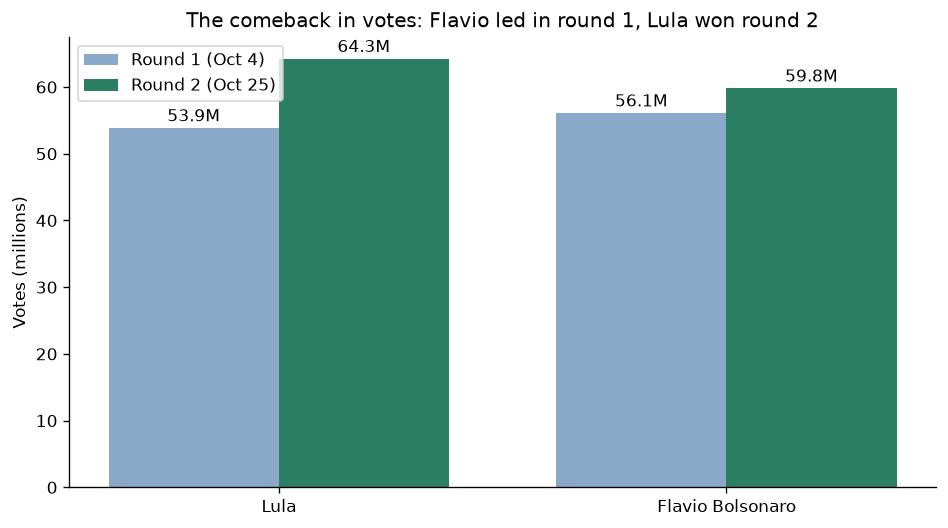

In [5]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
# Chart 1: the comeback in votes, round 1 vs round 2, for the two finalists.
nat = pd.read_csv(PROC / "national_2026.csv")
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = ["Lula", "Flavio Bolsonaro"]
r1_vals = [nat[nat["NR_TURNO"] == 1]["lula"].iloc[0] / 1e6, nat[nat["NR_TURNO"] == 1]["flavio"].iloc[0] / 1e6]
r2_vals = [nat[nat["NR_TURNO"] == 2]["lula"].iloc[0] / 1e6, nat[nat["NR_TURNO"] == 2]["flavio"].iloc[0] / 1e6]
x = range(2); w = 0.38
ax.bar([i - w/2 for i in x], r1_vals, width=w, label="Round 1 (Oct 4)", color="#8aa8c8")
ax.bar([i + w/2 for i in x], r2_vals, width=w, label="Round 2 (Oct 25)", color="#2a7f62")
for i, v in enumerate(r1_vals): ax.text(i - w/2, v + 1, f"{v:.1f}M", ha="center")
for i, v in enumerate(r2_vals): ax.text(i + w/2, v + 1, f"{v:.1f}M", ha="center")
ax.set_xticks(list(x)); ax.set_xticklabels(labels); ax.set_ylabel("Votes (millions)")
ax.set_title("The comeback in votes: Flavio led in round 1, Lula won round 2")
ax.legend(); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(CHARTS / "02_rounds.png"); plt.show()

### Turnout: more people voted in round 2, and abstention fell to about 19%

Turnout rose from 78.92% in round 1 to 80.78% in round 2, about 3.0 million more voters showed up. Abstention in round 2, about 19%, was reported as the lowest ever for a Brazilian presidential election. Remember Toy B from Chapter 1: when turnout moves by millions, the result can move with it even if nobody changes their mind. Chapter 3 measures exactly how much of Lula's gain that turnout rise could cover, and how much must have come from elsewhere.

### Lula's round-2 share, state by state

Lula did not win everywhere, he won the runoff nationally while losing several states by wide margins. That geography matters for Chapter 5: a gain concentrated in a handful of places would look very different from a gain spread across the country. The chart below (round-2 Lula share of valid votes, by state) is the first hint that the gain was broad.

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed


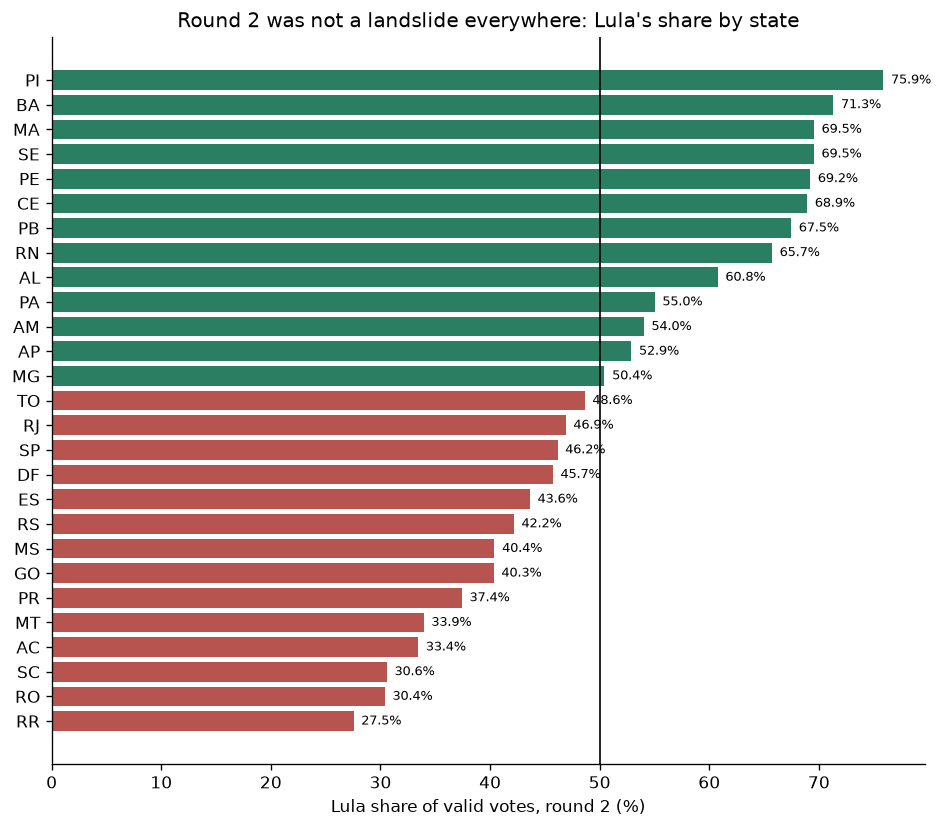

States (of 27) where Lula won round 2: 13
States where Flavio won round 2: 14


In [6]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
st = pd.read_csv(PROC / "state_2026.csv")
s2 = st[(st["NR_TURNO"] == 2) & (st["SG_UF"] != "ZZ")].copy()
s2["lula_share"] = s2["lula_share_valid"] * 100
s2 = s2.sort_values("lula_share")
fig, ax = plt.subplots(figsize=(8, 7))
colors = ["#2a7f62" if v >= 50 else "#b85450" for v in s2["lula_share"]]
ax.barh(s2["SG_UF"], s2["lula_share"], color=colors)
ax.axvline(50, color="black", linewidth=1)
ax.set_xlabel("Lula share of valid votes, round 2 (%)")
ax.set_title("Round 2 was not a landslide everywhere: Lula's share by state")
ax.spines[["top", "right"]].set_visible(False)
for i, v in enumerate(s2["lula_share"]):
    ax.text(v + 0.7, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(CHARTS / "02_state_share.png"); plt.show()
print(f"States (of 27) where Lula won round 2: {(s2['lula_share'] >= 50).sum()}")
print(f"States where Flavio won round 2: {(s2['lula_share'] < 50).sum()}")

## The historic first

Since Brazil returned to direct presidential elections under the 1988 Constitution, **no candidate who finished second in round 1 had ever gone on to win the runoff**, until 2026. The table below lists every runoff since 1989. Two elections (1994, 1998) had no runoff at all because the winner passed 50% in round 1.

| Election | Round-1 leader | Round-1 lead | Runoff winner | Did the leader win? |
|---|---|---|---|---|
| 1989 | Fernando Collor | 13.3 points | Fernando Collor | Yes |
| 1994 | Fernando Henrique Cardoso, won outright in round 1 |, | (no runoff) |, |
| 1998 | Fernando Henrique Cardoso, won outright in round 1 |, | (no runoff) |, |
| 2002 | Lula | 23.2 points | Lula | Yes |
| 2006 | Lula | 7.0 points | Lula | Yes |
| 2010 | Dilma Rousseff | 14.3 points | Dilma Rousseff | Yes |
| 2014 | Dilma Rousseff | 8.0 points | Dilma Rousseff | Yes |
| 2018 | Jair Bolsonaro | 16.8 points | Jair Bolsonaro | Yes |
| 2022 | Lula | 5.2 points | Lula | Yes |
| **2026** | **Flávio Bolsonaro** | **1.9 points** | **Lula** | **No, the first reversal** |

Sources for this table: TSE national results (the 2026 row is computed from the TSE files in this project and matches the verified totals; the 2002–2022 leads are the TSE-based series reproduced in the pre-election runoff analysis cited in `BUILD_REPORT.md`; the 1989 figures are the TSE/Wikipedia-recorded first-round shares, Collor 30.48% vs Lula 17.19%). Two things make 2026's reversal less mysterious than it first looks: the round-1 lead was by far the narrowest of any runoff (1.9 points, against 5.2 at the previous closest), and the pool of voters who still had to choose in round 2 was enormous, about 9.3 million eliminated-candidate votes plus about 3.0 million extra voters who turned out. Chapter 3 tests whether those pools actually add up.

**Takeaway.** A narrow round-1 lead, a huge pool of undecided-between-rounds votes, a turnout rise, and a historic reversal, all four are true at once. The next chapter asks the only question that can settle how the comeback happened in arithmetic terms: *where, exactly, did Lula's extra ~10 million votes come from?*